# Do HumanEval+ and MBPP+ rank models the same way?

- This notebook checks whether coding skill transfers between 2 benchmarks,
  and how many of their tasks carry information (Milestone 3)
  - It is Study E of `preregistration_3.md`, whose design and predictions
    were committed before any of it was run
  - The agents are 18 models with a greedy answer to every task of both
    benchmarks: 12 public EvalPlus models of 2023 and our 6 local models
- The pedagogical arc:
  - The scores of the 18 models on both benchmarks
  - How reliable each benchmark is, i.e., how much of the spread of the
    scores is the models and how much is the luck of the tasks
  - How well the 2 rankings agree, before and after removing task luck
  - Which models do better on one benchmark than a typical model does
  - How many equally informative tasks each benchmark is worth
  - The same agreement on the 89 models of the EvalPlus leaderboard
  - Which predictions held

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import pandas as pd
import scipy.stats

import helpers.hnotebook as hnotebook

import skill_vs_luck_runs_utils as rutils
import skill_vs_luck_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
rutils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmpvs1zvq7z.json --HistoryManager.hist_file=:memory:


# Part 1: The 18 models on both benchmarks

## Cell 1.1: Load the greedy answers

- Public models: the EvalPlus greedy samples, scored by
  `score_coding_runs.py`
- Local models: the first greedy run, one-shot, of phase 1 (DeepSeek Coder
  1.3B, CodeQwen 7B, OpenCoder 8B) and of Study D (DeepSeek Coder 6.7B,
  Llama 3.1 8B, CodeGemma 7B)

In [3]:
# Settings of the analysis.
config = {
    "phase_1_dir": "data/coding_runs",
    "phase_2_dir": "data/coding_runs_phase2",
    "leaderboard_file": "data/evalplus_leaderboard.csv",
    "benchmarks": ["humaneval", "mbpp"],
    "n_splits": 1000,
    "n_boot": 2000,
    "seed": 0,
    "figsize": (10, 5),
}
# Greedy scores of the public models and of the local models of phase 1, and
# of the 3 models of Study D.
phase_1_scores = rutils.load_scores(config["phase_1_dir"], pattern="*_t0.csv.gz")
phase_2_scores = rutils.load_scores(
    config["phase_2_dir"], pattern="local_*_t0.csv.gz"
)
phase_2_scores = phase_2_scores[
    phase_2_scores["model"].isin(rutils.PHASE_2_MODELS)
]
scores = pd.concat([phase_1_scores, phase_2_scores], ignore_index=True)
agents = [("evalplus", model) for model in rutils.TRANSFER_PUBLIC_MODELS] + [
    ("local", model) for model in rutils.PHASE_1_MODELS + rutils.PHASE_2_MODELS
]
outcomes = {}
for benchmark in config["benchmarks"]:
    matrix = rutils.get_greedy_matrix(scores, benchmark, agents)
    matrix.index = [rutils.get_model_label(model) for model in matrix.index]
    outcomes[benchmark] = matrix
    print(f"{benchmark}: {matrix.shape[0]} models x {matrix.shape[1]} tasks")

humaneval: 18 models x 164 tasks
mbpp: 18 models x 378 tasks


## Cell 1.2: Scores of the 18 models

In [4]:
# Show the share of tasks each model solves, in %.
model_scores = pd.DataFrame(
    {
        "humaneval_plus": 100 * outcomes["humaneval"].mean(axis=1),
        "mbpp_plus": 100 * outcomes["mbpp"].mean(axis=1),
    }
).sort_values("humaneval_plus", ascending=False)
display(model_scores.round(1))

,humaneval_plus,mbpp_plus
gpt-4-1106-preview,81.7,73.5
opencoder 8b,79.3,70.9
codeqwen 7b,78.7,69.6
deepseek-coder 6.7b,71.3,63.8
llama3.1 8b,64.0,63.2
deepseek-coder 1.3b,59.1,53.4
codegemma 7b,51.2,56.3
code-llama-34b,43.9,55.3
code-llama-13b,37.2,51.9
code-llama-7b,34.1,46.0


# Part 2: How reliable is each benchmark?

## Cell 2.1: KR-20 and split-half reliability

- KR-20 is the share of the spread of the scores that comes from the models,
  not from the luck of which tasks were drawn
- The split-half reliability correlates the scores on 2 random halves of the
  tasks and steps it up to the whole benchmark; it should be close to KR-20

In [5]:
# Compute both reliabilities of each benchmark.
reliability = pd.DataFrame(
    {
        benchmark: {
            "n_tasks": matrix.shape[1],
            "kr20": utils.compute_kr20(matrix),
            "split_half": utils.compute_split_half_reliability(
                matrix, n_splits=config["n_splits"], seed=config["seed"]
            ),
        }
        for benchmark, matrix in outcomes.items()
    }
).T
display(reliability.round(4))

,n_tasks,kr20,split_half
humaneval,164.0,0.9858,0.9887
mbpp,378.0,0.9804,0.9833


# Part 3: Do the 2 benchmarks agree?

## Cell 3.1: Correlation of the 2 rankings, before and after task luck

- The corrected correlation divides the Pearson correlation by the square
  root of the product of the 2 KR-20 values
  - 1 means the 2 benchmarks measure the same skill, and any disagreement is
    task luck
- The 95% intervals resample the models and the tasks of each benchmark

In [6]:
# Compare the rankings of the 18 models.
transfer = utils.compute_transfer(
    outcomes["humaneval"],
    outcomes["mbpp"],
    n_boot=config["n_boot"],
    seed=config["seed"],
)
display(transfer.round(4).to_frame("HumanEval+ vs MBPP+"))

,HumanEval+ vs MBPP+
pearson,0.9742
spearman,0.9835
kr20_a,0.9858
kr20_b,0.9804
corrected,0.9910
spearman_low,0.8068
spearman_high,0.9963
corrected_low,0.9209
corrected_high,1.0044


## Cell 3.2: Models that do better on one benchmark

- The residual of a model is how much more it gains on HumanEval+, on the
  logit scale, than the median model does
  - Positive: better on HumanEval+ than its MBPP+ score suggests; negative:
    better on MBPP+
  - `gap_points` is the same gap in HumanEval+ points
- A model is benchmark-specific when the 95% interval of its residual,
  which resamples the tasks, excludes 0

In [7]:
# Find the benchmark-specific models.
residuals = utils.compute_benchmark_residuals(
    outcomes["humaneval"],
    outcomes["mbpp"],
    n_boot=config["n_boot"],
    seed=config["seed"],
)
display(residuals.sort_values("residual", ascending=False).round(3))

,score_a,score_b,residual,residual_low,residual_high,gap_points,specific
codeqwen 7b,0.787,0.696,1.004,0.557,1.433,21.270,True
gpt-4-1106-preview,0.817,0.735,0.999,0.529,1.443,19.620,True
opencoder 8b,0.793,0.709,0.977,0.545,1.361,20.340,True
deepseek-coder 6.7b,0.713,0.638,0.877,0.461,1.238,20.485,True
deepseek-coder 1.3b,0.591,0.534,0.764,0.376,1.091,18.881,True
llama3.1 8b,0.640,0.632,0.566,0.167,0.919,13.781,True
codegemma 7b,0.512,0.563,0.328,-0.004,0.623,8.154,False
code-llama-34b,0.439,0.553,0.079,-0.233,0.328,1.927,False
code-llama-7b,0.341,0.460,0.040,-0.260,0.233,0.901,False
codegen-6b,0.256,0.381,-0.040,-0.372,0.141,-0.778,False


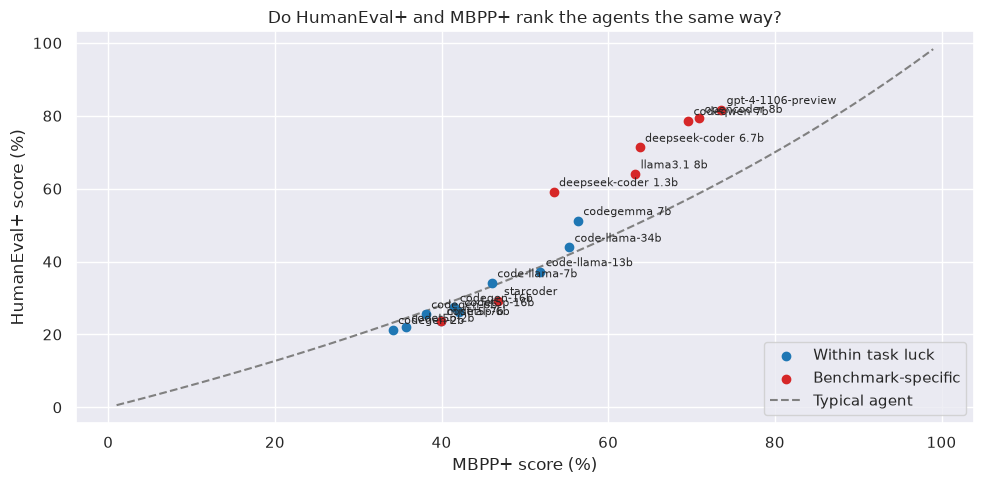

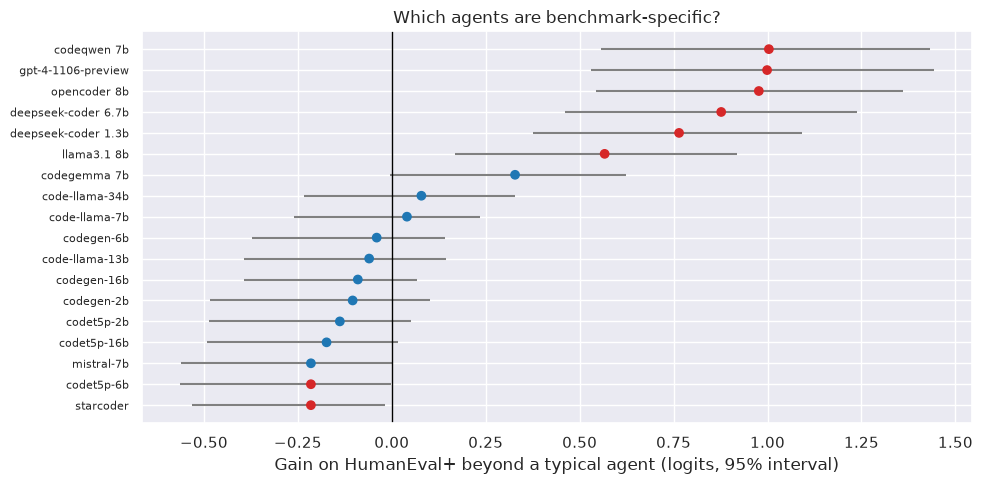

In [8]:
# Plot the 2 scores of each model and the residuals.
utils.plot_benchmark_scores(
    residuals, name_a="HumanEval+", name_b="MBPP+", figsize=config["figsize"]
)
utils.plot_benchmark_residuals(
    residuals, name_a="HumanEval+", figsize=config["figsize"]
)

## Cell 3.3: Chat and base models with the same MBPP+ score (extra look)

- Not in `preregistration_3.md`: added after Cell 3.2 showed that the 7 chat
  models (GPT-4 Turbo and the 6 local ones) all lie above the typical model
- A steeper HumanEval+ scale would also put the best models above the curve,
  so this cell compares models with the same MBPP+ score, where no
  extrapolation is needed
- For each chat model, the base model of 2023 with the closest MBPP+ score,
  kept when the 2 MBPP+ scores are within 3 points

In [9]:
# Pair each chat model with the closest base model on MBPP+.
chat_models = ["gpt-4-1106-preview"] + [
    rutils.get_model_label(model)
    for model in rutils.PHASE_1_MODELS + rutils.PHASE_2_MODELS
]
base = model_scores.drop(index=chat_models)
pairs = []
for chat_model in chat_models:
    mbpp_gaps = (
        base["mbpp_plus"] - model_scores.loc[chat_model, "mbpp_plus"]
    ).abs()
    base_model = mbpp_gaps.idxmin()
    pairs.append(
        {
            "chat_model": chat_model,
            "base_model": base_model,
            "mbpp_gap": mbpp_gaps.min(),
            "humaneval_gain": model_scores.loc[chat_model, "humaneval_plus"]
            - model_scores.loc[base_model, "humaneval_plus"],
        }
    )
pairs = pd.DataFrame(pairs).set_index("chat_model")
display(pairs[pairs["mbpp_gap"] <= 3].round(1))

,base_model,mbpp_gap,humaneval_gain
chat_model,,,
deepseek-coder 1.3b,code-llama-13b,1.6,22.0
codegemma 7b,code-llama-34b,1.1,7.3


# Part 4: How many tasks carry information?

## Cell 4.1: Effective size of each benchmark under a 2PL fit

- The 2PL model of Milestone 3, fit with SVI as for SWE-bench Verified
- The information of each task is averaged over the 18 fitted abilities,
  and the effective size is the number of equally informative tasks the
  benchmark is worth (decision D-3)
- Tasks with mixed outcomes are those that some models solve and some fail

In [10]:
# Fit each benchmark and measure its effective size.
fits = {}
effective_rows = {}
for benchmark, matrix in outcomes.items():
    fit = utils.fit_irt_2pl(matrix, method="svi", seed=config["seed"])
    information = utils.compute_task_information(
        fit["agents"]["ability"], fit["tasks"]
    )
    fits[benchmark] = fit
    effective_rows[benchmark] = {
        "n_tasks": matrix.shape[1],
        "n_mixed_tasks": utils.count_informative_tasks(matrix),
        "effective_size": utils.compute_effective_size(information),
    }
effective = pd.DataFrame(effective_rows).T
effective["effective_share"] = effective["effective_size"] / effective["n_tasks"]
display(effective.round(3))

,n_tasks,n_mixed_tasks,effective_size,effective_share
humaneval,164.0,135.0,118.508,0.723
mbpp,378.0,299.0,214.480,0.567


## Cell 4.2: Do the fitted abilities agree across the 2 benchmarks?

In [11]:
# Correlate the fitted abilities, which weigh the tasks by information.
abilities = pd.DataFrame(
    {benchmark: fit["agents"]["ability"] for benchmark, fit in fits.items()}
)
ability_spearman = scipy.stats.spearmanr(
    abilities["humaneval"], abilities["mbpp"]
).statistic
print(f"Spearman correlation of the fitted abilities: {ability_spearman:.3f}")

Spearman correlation of the fitted abilities: 0.975


# Part 5: Does the agreement hold on a bigger leaderboard?

## Cell 5.1: The 89 models of the EvalPlus leaderboard

- The snapshot of `data/evalplus_leaderboard.csv`, made by
  `fetch_evalplus_data.py` on 2026-11-26
- Only the scores are public, so this check has no task luck correction

89 models, Spearman correlation 0.939


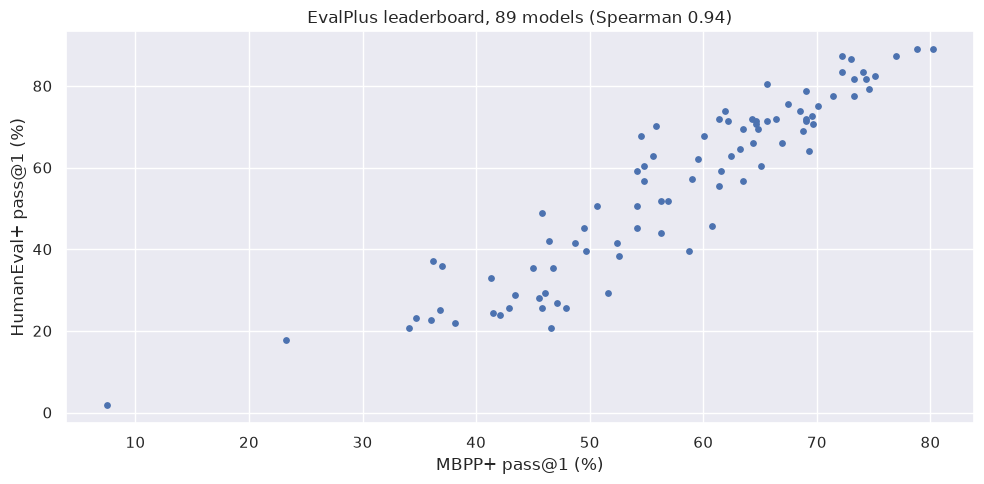

In [12]:
# Correlate the published HumanEval+ and MBPP+ scores.
leaderboard = pd.read_csv(config["leaderboard_file"])
leaderboard = leaderboard.dropna(subset=["humaneval_plus", "mbpp_plus"])
leaderboard_spearman = scipy.stats.spearmanr(
    leaderboard["humaneval_plus"], leaderboard["mbpp_plus"]
).statistic
print(
    f"{len(leaderboard)} models, Spearman correlation {leaderboard_spearman:.3f}"
)
rutils.plot_leaderboard_agreement(leaderboard, figsize=config["figsize"])

# Part 6: Which predictions held?

## Cell 6.1: Predictions against the results

In [13]:
# Check the predictions E1 to E6 of `preregistration_3.md`.
predictions = rutils.check_transfer_predictions(
    transfer=transfer,
    residuals=residuals,
    effective=effective,
    leaderboard_spearman=leaderboard_spearman,
)
display(predictions)

,prediction,observed,holds
E1,KR-20 is at least 0.95 on both benchmarks,"HumanEval+ 0.986, MBPP+ 0.980",True
E2,The Spearman correlation is at least 0.80,0.983 (95% interval 0.807 to 0.996),True
E3,"The corrected correlation is below 0.95, inter...",0.991 (95% interval 0.921 to 1.004),False
E4,At least 2 of the 18 models are benchmark-spec...,8 of 18 models,True
E5,"Effective size is 30% to 70% of the tasks, sma...","HumanEval+ 72.3%, MBPP+ 56.7%",False
E6,The leaderboard Spearman correlation is at lea...,0.939,True


# Part 7: Takeaways

- Both benchmarks rank the 18 models reliably (KR-20 0.986 on HumanEval+ and
  0.980 on MBPP+), and they rank them almost the same way
  - The Spearman correlation is 0.98, and without task luck the correlation
    is 0.99, with a 95% interval that reaches 1.00 (E3 did not hold): the
    order of the models transfers
- The scale does not transfer: 6 of the 7 chat models score 14 to 21
  HumanEval+ points more than a typical model with the same MBPP+ score, and
  2 base models (StarCoder and CodeT5+ 6B) about 4 to 5 points less, so 8 of
  the 18 models are benchmark-specific (E4 held)
  - CodeGemma 7B, the 7th chat model, is 8 points above, within task luck
  - At the same MBPP+ score, DeepSeek Coder 1.3B beats Code Llama 13B by 22.0
    HumanEval+ points, and CodeGemma 7B beats Code Llama 34B by 7.3 (Cell
    3.3, an extra look)
  - Either the chat models were tuned toward HumanEval-style tasks, or their
    chat prompt suits HumanEval+ better than the completion prompt of the
    public samples; this data cannot tell the 2 apart
  - So a gap between 2 models of different families on 1 benchmark says
    little about their gap on the other, even though the order holds
- HumanEval+ is worth about 119 equally informative tasks for these models
  (72% of its 164) and MBPP+ about 214 (57% of its 378); 29 and 79 tasks have
  the same outcome for all 18 models (E5 did not hold, since HumanEval+ is
  above 70%)
- On the 89 models of the EvalPlus leaderboard the 2 benchmarks also agree
  (Spearman 0.94, E6 held)
- 4 of the 6 predictions held (E1, E2, E4, and E6), and E3 and E5 did not